# code_068 · Temporal backtesting and delayed labels

**Book:** section 14.2. A self-contained deployment-matched validation laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_14_GUIDE.md), [run evidence](../CHAPTER_14_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_068).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1468;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1468


<a id="arrival"></a>
## A past cutoff need not have a resolved target

Generate 310 days. At daily cutoff c, feature vector [x[c],mean(x[c-6:c+1])] uses observed history only, with x=sin(2*pi*t/30)+.005*t+Gaussian(.3). Latent daily response = x + .4*previous x + Gaussian(.5). An alarm asks whether any response in (c,c+h] exceeds 2.4, separately for h=1 and h=7. Labels arrive at c+h+integer delay 0–10. They can train an origin-o model only when arrival<=o. Fixed logistic C=1 at origins 110,150,190,230 predicts the next 20 cutoffs, without refitting within that block. Future predictors arrive at each prediction cutoff; the model remains fixed. These generated eventual labels permit retrospective scoring, not their use during fitting.


,horizon,origin,strategy,train_rows,unarrived_admitted,positives,assessment_rows,log_loss,brier,baseline_brier
0,1,110,expanding,99,0,2,20,0.265396,0.084087,0.094858
1,1,110,rolling90,86,0,2,20,0.261641,0.083168,0.094240
2,1,110,invalid_event_only,103,4,2,20,0.269109,0.084760,0.095023
3,1,150,expanding,140,0,4,20,0.409260,0.138731,0.182500
4,1,150,rolling90,87,0,4,20,0.405224,0.135031,0.174290
5,1,150,invalid_event_only,143,3,4,20,0.409271,0.138835,0.182816
6,1,190,expanding,178,0,1,20,0.115202,0.027978,0.048031
7,1,190,rolling90,85,0,1,20,0.127807,0.030222,0.052076
8,1,190,invalid_event_only,183,5,1,20,0.124104,0.031579,0.049839
9,1,230,expanding,218,0,5,20,0.411057,0.140247,0.204591


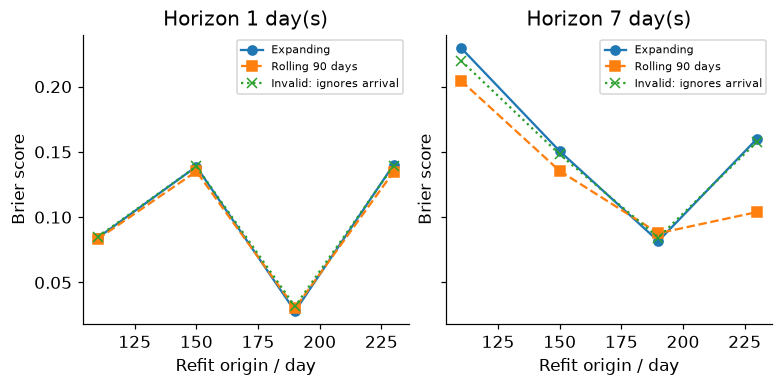

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import log_loss,brier_score_loss
t=np.arange(310);x=np.sin(2*np.pi*t/30)+.005*t+rng.normal(0,.3,len(t));response=x+.4*np.r_[x[0],x[:-1]]+rng.normal(0,.5,len(t));cut=np.arange(7,290);X=np.array([[x[c],x[c-6:c+1].mean()] for c in cut]);origins=[110,150,190,230];rows=[]
for h in [1,7]:
 y=np.array([int(np.max(response[c+1:c+h+1])>2.4) for c in cut]);arrival=cut+h+rng.integers(0,11,len(cut));assert np.all(arrival>=cut+h)
 for origin in origins:
  assessment=(cut>=origin)&(cut<origin+20)
  for strategy in ['expanding','rolling90','invalid_event_only']:
   admitted=(cut<origin)&((arrival<=origin) if strategy!='invalid_event_only' else True)
   if strategy=='rolling90':admitted&=cut>=origin-90
   assert not set(cut[admitted])&set(cut[assessment])
   if strategy!='invalid_event_only':assert np.all(arrival[admitted]<=origin)
   train_y=y[admitted];assert len(train_y)>0
   p=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=1000)).fit(X[admitted],train_y).predict_proba(X[assessment])[:,1] if len(np.unique(train_y))==2 else np.full(assessment.sum(),train_y.mean())
   baseline=np.full(assessment.sum(),train_y.mean());rows.append({'horizon':h,'origin':origin,'strategy':strategy,'train_rows':int(admitted.sum()),'unarrived_admitted':int(np.sum(arrival[admitted]>origin)),'positives':int(y[assessment].sum()),'assessment_rows':int(assessment.sum()),'log_loss':float(log_loss(y[assessment],p,labels=[0,1])),'brier':float(brier_score_loss(y[assessment],p)),'baseline_brier':float(brier_score_loss(y[assessment],baseline))})
assert all(r['unarrived_admitted']==0 for r in rows if r['strategy']!='invalid_event_only')
RESULTS['backtest']=rows;RESULTS['protocol']={'origins':origins,'assessment_cutoffs_per_origin':20,'refit_within_block':False,'fixed_C':1,'assessment_labels':'eventual retrospective only','overlapping_horizon_targets':'not independent trials'};display(pd.DataFrame(rows))
fig,axes=plt.subplots(1,2,figsize=(7,3.4),sharey=True)
for ax,h in zip(axes,[1,7]):
 for strategy,style in [('expanding','-o'),('rolling90','--s'),('invalid_event_only',':x')]:
  data=[r for r in rows if r['horizon']==h and r['strategy']==strategy];ax.plot(origins,[r['brier'] for r in data],style,label={'expanding':'Expanding','rolling90':'Rolling 90 days','invalid_event_only':'Invalid: ignores arrival'}[strategy])
 ax.set(title=f'Horizon {h} day(s)',xlabel='Refit origin / day',ylabel='Brier score');ax.legend(fontsize=7)
plt.show()


<a id="overlap"></a>
## Shared raw measurements do not make every operational replay invalid

Context is (c-6,c], target (c,c+7]. Adjacent cutoffs 80/81 share history and target days. Splitting these rows randomly and claiming independent trials or allowing the later resolved label into the earlier fit is invalid. A chronological replay can legitimately reuse already observed history at consecutive predictions. A stricter assessment of separate raw intervals can instead end training at c=80, resolve its label no later than 97 under this delay rule, and start final cutoff c=98: its context begins after all training target days. This purges raw-interval overlap and admits mature labels in this fixture; it does not prove stochastic independence. Operational gaps must reflect actual horizons, arrivals and retraining cadence, not an arbitrary number of rows.


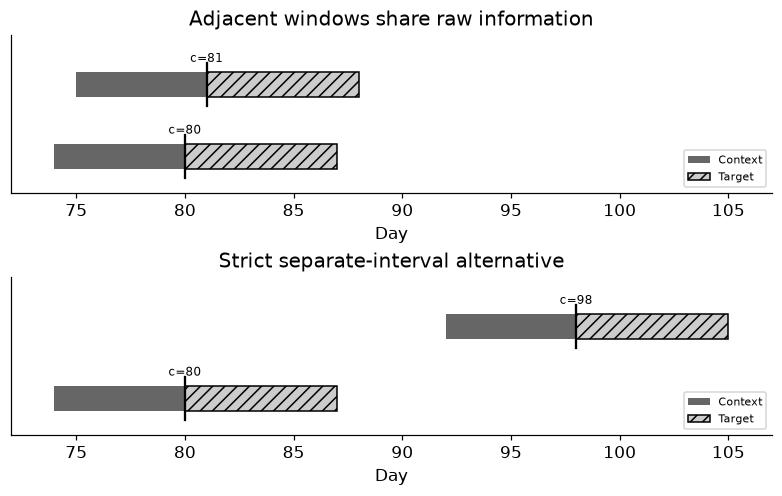

In [3]:
def context(c):return set(range(c-5,c+1))
def target(c):return set(range(c+1,c+8))
assert context(80)&context(81) and target(80)&target(81)
assert not (context(80)|target(80))&(context(98)|target(98))
assert 80+7+10<=98
RESULTS['overlap_fixture']={'adjacent_shared_context_days':sorted(context(80)&context(81)),'adjacent_shared_target_days':sorted(target(80)&target(81)),'strict_cutoffs':[80,98],'strict_raw_overlap':0,'latest_training_label_arrival':97,'independence_not_proved':True}
fig,axes=plt.subplots(2,1,figsize=(7,4.4))
for ax,cs,title in zip(axes,[(80,81),(80,98)],['Adjacent windows share raw information','Strict separate-interval alternative']):
 for j,c in enumerate(cs):
  ax.barh(j,6,left=c-6,height=.35,color='.4',label='Context' if j==0 else None);ax.barh(j,7,left=c,height=.35,color='.8',edgecolor='black',hatch='///',label='Target' if j==0 else None);ax.plot([c,c],[j-.3,j+.3],color='black');ax.text(c,j+.32,f'c={c}',ha='center',fontsize=8)
 ax.set(xlim=(72,107),ylim=(-.5,1.7),yticks=[],xlabel='Day',title=title);ax.legend(fontsize=7,loc='lower right')
plt.show()


In [4]:
summary={'example_id':'code_068','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['expanding and rolling origins', 'one-day and seven-day horizons', 'label-arrival admission', 'overlap versus availability and independence'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["expanding and rolling origins", "one-day and seven-day horizons", "label-arrival admission", "overlap versus availability and independence"], "elapsed_seconds": 0.289, "example_id": "code_068", "hardware": "Darwin arm64 CPU", "results": {"backtest": [{"assessment_rows": 20, "baseline_brier": 0.09485766758494033, "brier": 0.08408651056405533, "horizon": 1, "log_loss": 0.2653955308743356, "origin": 110, "positives": 2, "strategy": "expanding", "train_rows": 99, "unarrived_admitted": 0}, {"assessment_rows": 20, "baseline_brier": 0.09424012979989185, "brier": 0.08316765421521058, "horizon": 1, "log_loss": 0.26164118975028344, "origin": 110, "positives": 2, "strategy": "rolling90", "train_rows": 86, "unarrived_admitted": 0}, {"assessment_rows": 20, "baseline_brier": 0.09502309359977376, "brier": 0.08475960546523208, "horizon": 1, "log_loss": 0.26910920477481703, "origin": 110, "positives": 2, "strategy": "invalid_event_only", "train_rows": 